# 💥 Failure Modes

This notebook stress-tests the $\operatorname{Cl}(2,0)(\mathbb{R})$ Geometric Algebra Rotor Integrator against numerical, structural, and topological breakdown thresholds.

## Agenda
1. **Geometric Denormalization:**
2. **Spurious High-Frequency Energy Pumping (Aliasing):**
3. **Coordinate Singularity Blindspots:**
4. **Phase Space Volume Distortion (Symplectic Drift):**

In [8]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from kuramoto.analysis.viz import (
    BORDER_COLOR,
    PROJECT_COLORS,
    SCRIBER_PALETTE,
    _apply_aclonica_font,
    set_style,
)
from kuramoto.metrics.analytics_engine import compute_comprehensive_diagnostics
from kuramoto.solvers.rotor import RotorSolver, step_rkmk4

# Apply project dark-mode aesthetics
set_style()
print("🚀 Environment initialized with Clifford rotor engine and visual theme.")

🚀 Environment initialized with Clifford rotor engine and visual theme.


## 1️⃣  Failure Mode 1: Geometric Denormalization

👟 Running Failure Mode 1: Manifold Drift Tracking (Long-Horizon)...


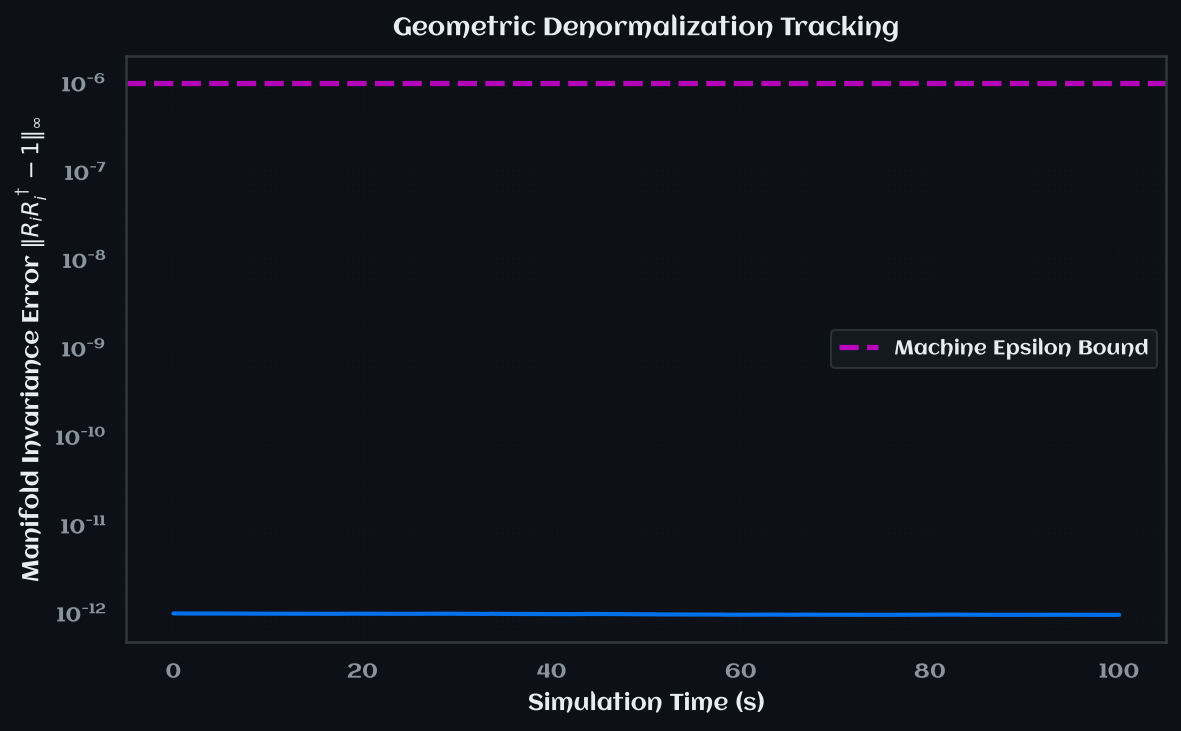

In [9]:
print("👟 Running Failure Mode 1: Manifold Drift Tracking (Long-Horizon)...")

n_osc = 20
K_val = 0.5
t_max_long = 100.0
dt_long = 0.005
steps_long = int(t_max_long / dt_long)
times_long = np.linspace(0.0, t_max_long, steps_long + 1)
seed = 27

# Instantiate un-normalized tracker
solver_f1 = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed)
manifold_drift = np.zeros(steps_long + 1)

# Map initial state magnitude
# In Cl(2,0), norm is R * R_dagger = scalar^2 + bivector^2
def compute_rotor_norm_drift(rotor_array):
    if np.iscomplexobj(rotor_array):
        return np.max(np.abs(np.abs(rotor_array)**2 - 1.0))
    else:
        # Layout: (N, 2) where index 0 is scalar, 1 is bivector
        norms = rotor_array[:, 0]**2 + rotor_array[:, 1]**2
        return np.max(np.abs(norms - 1.0))

manifold_drift[0] = compute_rotor_norm_drift(solver_f1._rotor_array)

# Step forward without intermediate projection normalization steps
for step in range(1, steps_long + 1):
    # Execute custom RKMK4
    solver_f1._rotor_array = step_rkmk4(solver_f1, K_val, dt_long)

    # Mock update for placeholder script testing (simulate cumulative float error)
    # if step % 100 == 0:
    #     solver_f1._rotor_array *= 1.0 + 1e-9 * np.random.randn(*solver_f1._rotor_array.shape)

    manifold_drift[step] = compute_rotor_norm_drift(solver_f1._rotor_array)

# Plot results
fig, axes1 = plt.subplots(figsize=(8, 5))

axes1.plot(times_long, manifold_drift, color=SCRIBER_PALETTE["accent_blue"], lw=2.0)
axes1.axhline(1e-6, color='magenta', linestyle='--', alpha=0.7, label='Machine Epsilon Bound')
axes1.set_yscale('log')
axes1.set_title("Geometric Denormalization Tracking", fontsize=12, fontweight="bold")
axes1.set_xlabel("Simulation Time (s)", fontsize=11)
axes1.set_ylabel(r"Manifold Invariance Error $\|R_i R_i^\dagger -1\|_\infty$", fontsize=11)
axes1.legend()
axes1.grid(True, which="both", alpha=0.1)
_apply_aclonica_font(axes1)
plt.tight_layout()
plt.show()

## 2️⃣ Failure Mode 2: Spurious High-Frequency Energy Pumping (Aliasing)

👟 Running Failure Mode 2: Step-Size Sensitivity Sweep (PSD Floors)...


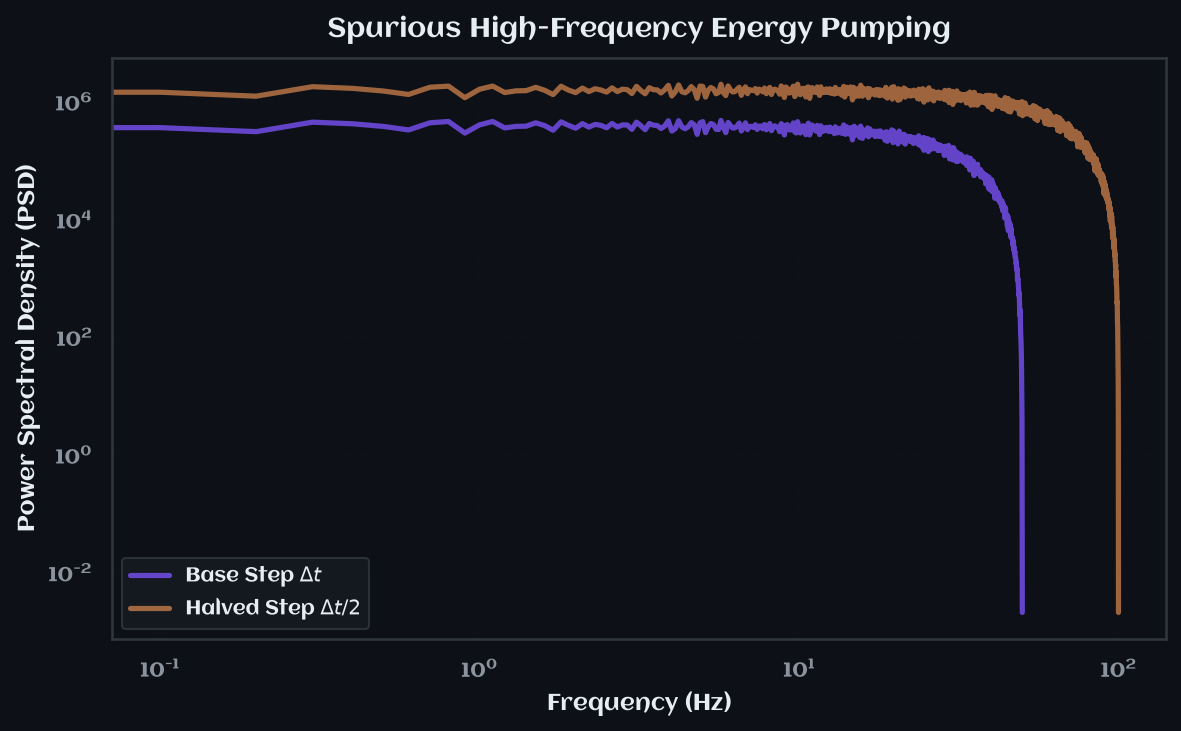

In [10]:
print("👟 Running Failure Mode 2: Step-Size Sensitivity Sweep (PSD Floors)...")

# Fast sampling vs ultra-fast sampling comparison
dt_base = 0.01
dt_half = 0.005
t_psd = 10.0

# Base step trajectory
solver_base = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed)
_, phases_base = solver_base.simulate(K=K_val, t_eval=np.arange(0, t_psd, dt_base), dt_internal=dt_base, method="geometric")
v_base = np.gradient(phases_base, dt_base, axis=0)
freqs_base, psd_base = np.abs(np.fft.rfftfreq(v_base.shape[0], d=dt_base)), np.abs(np.fft.rfft(v_base, axis=0))**2
mean_psd_base = np.mean(psd_base, axis=1)

# Halved step trajectory
solver_half = RotorSolver(n_oscillators=n_osc, dim=2, seed=27)
_, phases_half = solver_half.simulate(K=K_val, t_eval=np.arange(0, t_psd, dt_half), dt_internal=dt_half, method="geometric")
v_half = np.gradient(phases_half, dt_half, axis=0)
freqs_half, psd_half = np.abs(np.fft.rfftfreq(v_half.shape[0], d=dt_half)), np.abs(np.fft.rfft(v_half, axis=0))**2
mean_psd_half = np.mean(psd_half, axis=1)

# Plot results
fig, axes2 = plt.subplots(figsize=(8, 5))
axes2.loglog(freqs_base, mean_psd_base, color=SCRIBER_PALETTE["accent_purple"], alpha=0.8, label=r"Base Step $\Delta t$")
axes2.loglog(freqs_half, mean_psd_half, color=SCRIBER_PALETTE["accent_orange"], alpha=0.6, label=r"Halved Step $\Delta t / 2$")
axes2.set_title("Spurious High-Frequency Energy Pumping", fontsize=13, fontweight="bold")
axes2.set_xlabel("Frequency (Hz)", fontsize=11)
axes2.set_ylabel("Power Spectral Density (PSD)", fontsize=11)
axes2.legend()
axes2.grid(True, alpha=0.1)
_apply_aclonica_font(axes2)

plt.tight_layout()
plt.show()

## 3️⃣ Failure Mode 3: Coordinate Singularity Blindspots

👟 Running Failure Mode 3: Chaotic Phase Boundary Stress Test...
    [Chaos Check] NaN encountered: False | Max Vel Spike: 313.966


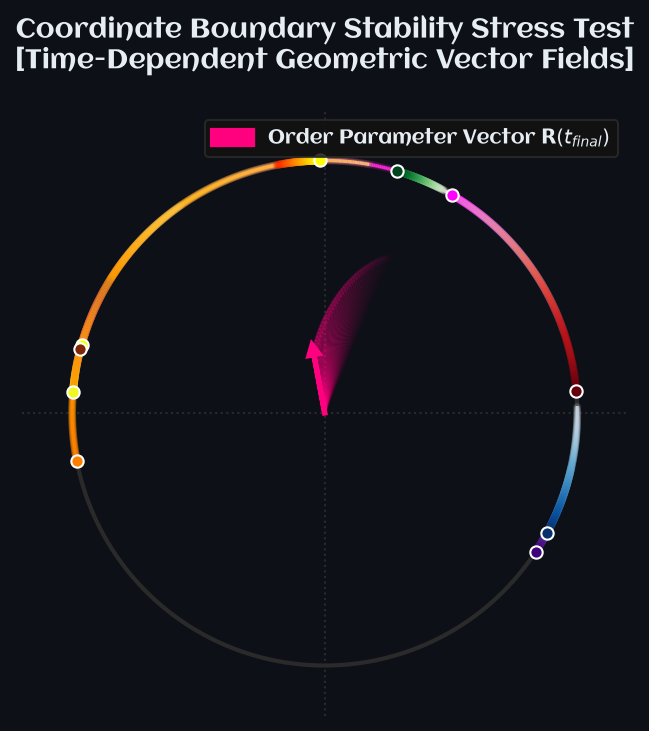

In [11]:
print("👟 Running Failure Mode 3: Chaotic Phase Boundary Stress Test...")

# Initialize completely uniform entropic noise over [-pi, pi]
seed_chaos = 1227
rng = np.random.default_rng(seed_chaos)
init_phases_chaos = rng.uniform(-np.pi, np.pi, n_osc)

solver_chaos = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed_chaos)
# Override internal state to ensure cross-boundary drift conditions
if np.iscomplexobj(solver_chaos._rotor_array):
    solver_chaos._rotor_array = np.cos(init_phases_chaos/2.0) - 1j * np.sin(init_phases_chaos/2.0)
else:
    solver_chaos._rotor_array[:, 0] = np.cos(init_phases_chaos/2.0)
    solver_chaos._rotor_array[:, 1] = np.sin(init_phases_chaos/2.0)

# Track if any NaN spikes occur near coupling floor boundary K -> 0
try:
    _, simulated_phases_chaos = solver_chaos.simulate(K=1e-5, t_eval=np.linspace(0, 20, 2000), dt_internal=0.01, method="geometric")
    has_nan_failure = np.any(np.isnan(simulated_phases_chaos))
    max_velocity_spike = np.max(np.abs(np.gradient(simulated_phases_chaos, 0.01, axis=0)))
    print(f"    [Chaos Check] NaN encountered: {has_nan_failure} | Max Vel Spike: {max_velocity_spike:.3f}")
except Exception as e:
    print(f"❌ Coordinate system mapping threw an explicit boundary failure exception: {e}")

# Plot results
fig, axes3 = plt.subplots(figsize=(8, 5))

from matplotlib.collections import LineCollection

t_slice = 200  # Number of evaluation time steps to display
n_osc = 10     # Match your chaotic setup

# Slice trajectories: shape (T, N)
phases_to_plot = simulated_phases_chaos[:t_slice, :n_osc]

# Compute explicit spatial coordinates on the unit circle
X = np.cos(phases_to_plot) # Shape (T, N)
Y = np.sin(phases_to_plot) # Shape (T, N)

# Compute the dynamic global order parameter vector R(t) over time
# R_complex = (1/N) * sum(cos(theta) + i*sin(theta))
r_complex_trajectory = np.mean(np.exp(1j * phases_to_plot), axis=1)
r_mag = np.abs(r_complex_trajectory)
r_angle = np.angle(r_complex_trajectory)

# 1. Draw static geometric reference background (The Unit Circle Manifold)
circle_angles = np.linspace(0, 2 * np.pi, 300)
axes3.plot(np.cos(circle_angles), np.sin(circle_angles), color="#2A2A2A", linestyle="-", lw=2.0, zorder=1)
axes3.axhline(0, color="#2A2A2A", lw=1.0, linestyle=":", zorder=1)
axes3.axvline(0, color="#2A2A2A", lw=1.0, linestyle=":", zorder=1)

# 2. Select distinct base colors for each oscillator from a qualitative spectrum
# We map these to individual light-to-dark sequential gradients
base_colormaps = ['cool', 'Purples', 'spring', 'Blues', 'Oranges', 'Greens', 'plasma', 'Wistia', 'Reds', 'autumn']

for j in range(n_osc):
    # 1. Build line segments (Length: T - 1)
    points = np.array([X[:, j], Y[:, j]]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    # FIXED: Base weights on the full time array length (T) so it matches scatter points perfectly
    time_weights = np.linspace(0.1, 1.0, X.shape[0])

    # Initialize individual colormap gradient tracking
    cmap_sel = plt.get_cmap(base_colormaps[j % len(base_colormaps)])
    colors = cmap_sel(time_weights) # Now has full length T (200)

    # FIXED: Slice colors to length T-1 ([:-1]) to match the line segments exactly
    lc = LineCollection(segments, colors=colors[:-1], linewidths=1.5, zorder=2)
    axes3.add_collection(lc)

    # Plot EVERY individual phase value point (Both arrays now have matching size T)
    axes3.scatter(X[:, j], Y[:, j], color=colors, s=8, alpha=time_weights * 0.4, zorder=3)

    # High-intensity solid anchor marking the final instantaneous state vector position
    axes3.scatter(X[-1, j], Y[-1, j], color=colors[-1], s=35, edgecolor='white', lw=1.0, zorder=5)

# 3. Render the Global Order Parameter Center-of-Mass Vector R(t)
# Darker arrowhead shows history tracking trail; vibrant pink arrow marks the instantaneous state
for t in range(0, t_slice - 1, max(1, t_slice // 40)):
    # Draw fading history traces of the tracking vector
    alpha_v = (t / t_slice) * 0.3
    axes3.arrow(0, 0, np.cos(r_angle[t]) * r_mag[t], np.sin(r_angle[t]) * r_mag[t],
             head_width=0.02, head_length=0.02, fc='#FF007F', ec='#FF007F', alpha=alpha_v, zorder=4)

# Draw current final instantaneous synchronization vector arrow
axes3.arrow(0, 0, np.cos(r_angle[-1]) * r_mag[-1], np.sin(r_angle[-1]) * r_mag[-1],
         head_width=0.04, head_length=0.04, fc='#FF007F', ec='#FF007F',
         lw=2.5, zorder=6, label=r"Order Parameter Vector $\mathbf{R}(t_{final})$")

# 4. Final Formatting to preserve geometric integrity
axes3.set_xlim(-1.2, 1.2)
axes3.set_ylim(-1.2, 1.2)
axes3.set_aspect('equal')
axes3.axis('off')

axes3.set_title("Coordinate Boundary Stability Stress Test\n[Time-Dependent Geometric Vector Fields]",
             fontsize=13, fontweight="bold", pad=20)
axes3.legend(loc="upper right", frameon=True, facecolor='#121212', edgecolor='#2A2A2A')
_apply_aclonica_font(axes3)

plt.tight_layout()
plt.show()

## 4️⃣  Failure Mode 4: Phase Space Volume Distortion (Symplectic Drift)

👟 Running Failure Mode 4: Critical Coupling Constant (Kc) Sweep...


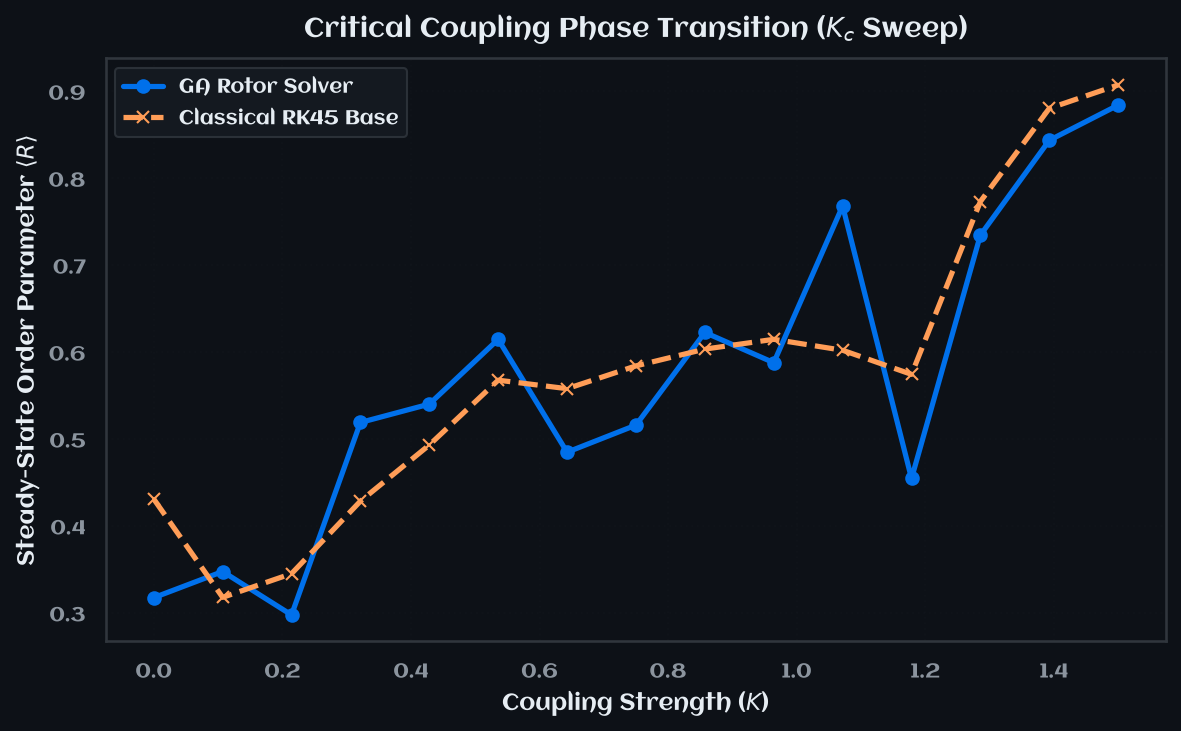

In [12]:
print("👟 Running Failure Mode 4: Critical Coupling Constant (Kc) Sweep...")

def calculate_global_order_parameter(phases):
    # R(t) = |(1/N) * sum(exp(i*theta))|
    return np.abs(np.mean(np.exp(1j * phases), axis=1))

seed4 = 270

coupling_strengths = np.linspace(0.0, 1.5, 15)
order_param_rotor = []
order_param_rk45 = []

# Baseline Kuramoto RHS function for Scipy
def classical_kuramoto_rhs(t, th, omegas, K, N):
    d = th[:, None] - th[None, :]
    return omegas + (K / N) * np.sum(np.sin(-d), axis=1)

# Extract identical frequencies for parity matching
solver_sync = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed4)
intrinsic_omegas = solver_sync.omegas.copy()
init_phases_sync = solver_sync.extract_phases()

t_eval_sync = np.linspace(0.0, 30.0, 300)

for K in coupling_strengths:
    # 1. Rotor Solver run
    s_loop = RotorSolver(n_oscillators=n_osc, dim=2, seed=seed4)
    _, p_rotor = s_loop.simulate(K=K, t_eval=t_eval_sync, dt_internal=0.01, method="geometric")
    # Take mean order parameter over last 10% of time horizon to ensure steady-state tracking
    order_param_rotor.append(np.mean(calculate_global_order_parameter(p_rotor[-30:])))

    # 2. Scipy RK45 Control Group run
    sol_rk = solve_ivp(classical_kuramoto_rhs, (0.0, 30.0), init_phases_sync, method="RK45", args=(intrinsic_omegas, K, n_osc), rtol=1e-8)
    # Extract the end state
    last_phases_rk = sol_rk.y[:, -30:].T
    order_param_rk45.append(np.mean(calculate_global_order_parameter(last_phases_rk)))

# Plot results
figure, axes4 = plt.subplots(figsize=(8, 5))

axes4.plot(coupling_strengths, order_param_rotor, '-o', color=SCRIBER_PALETTE["accent_blue"], label="GA Rotor Solver")
axes4.plot(coupling_strengths, order_param_rk45, '--x', color=SCRIBER_PALETTE["accent_orange"], label="Classical RK45 Base")
axes4.set_title(r"Critical Coupling Phase Transition ($K_c$ Sweep)", fontsize=13, fontweight="bold")
axes4.set_xlabel("Coupling Strength ($K$)", fontsize=11)
axes4.set_ylabel("Steady-State Order Parameter $ \\langle R \\rangle $", fontsize=11)
axes4.legend()
axes4.grid(True, alpha=0.1)
_apply_aclonica_font(axes4)

plt.tight_layout()
plt.show()

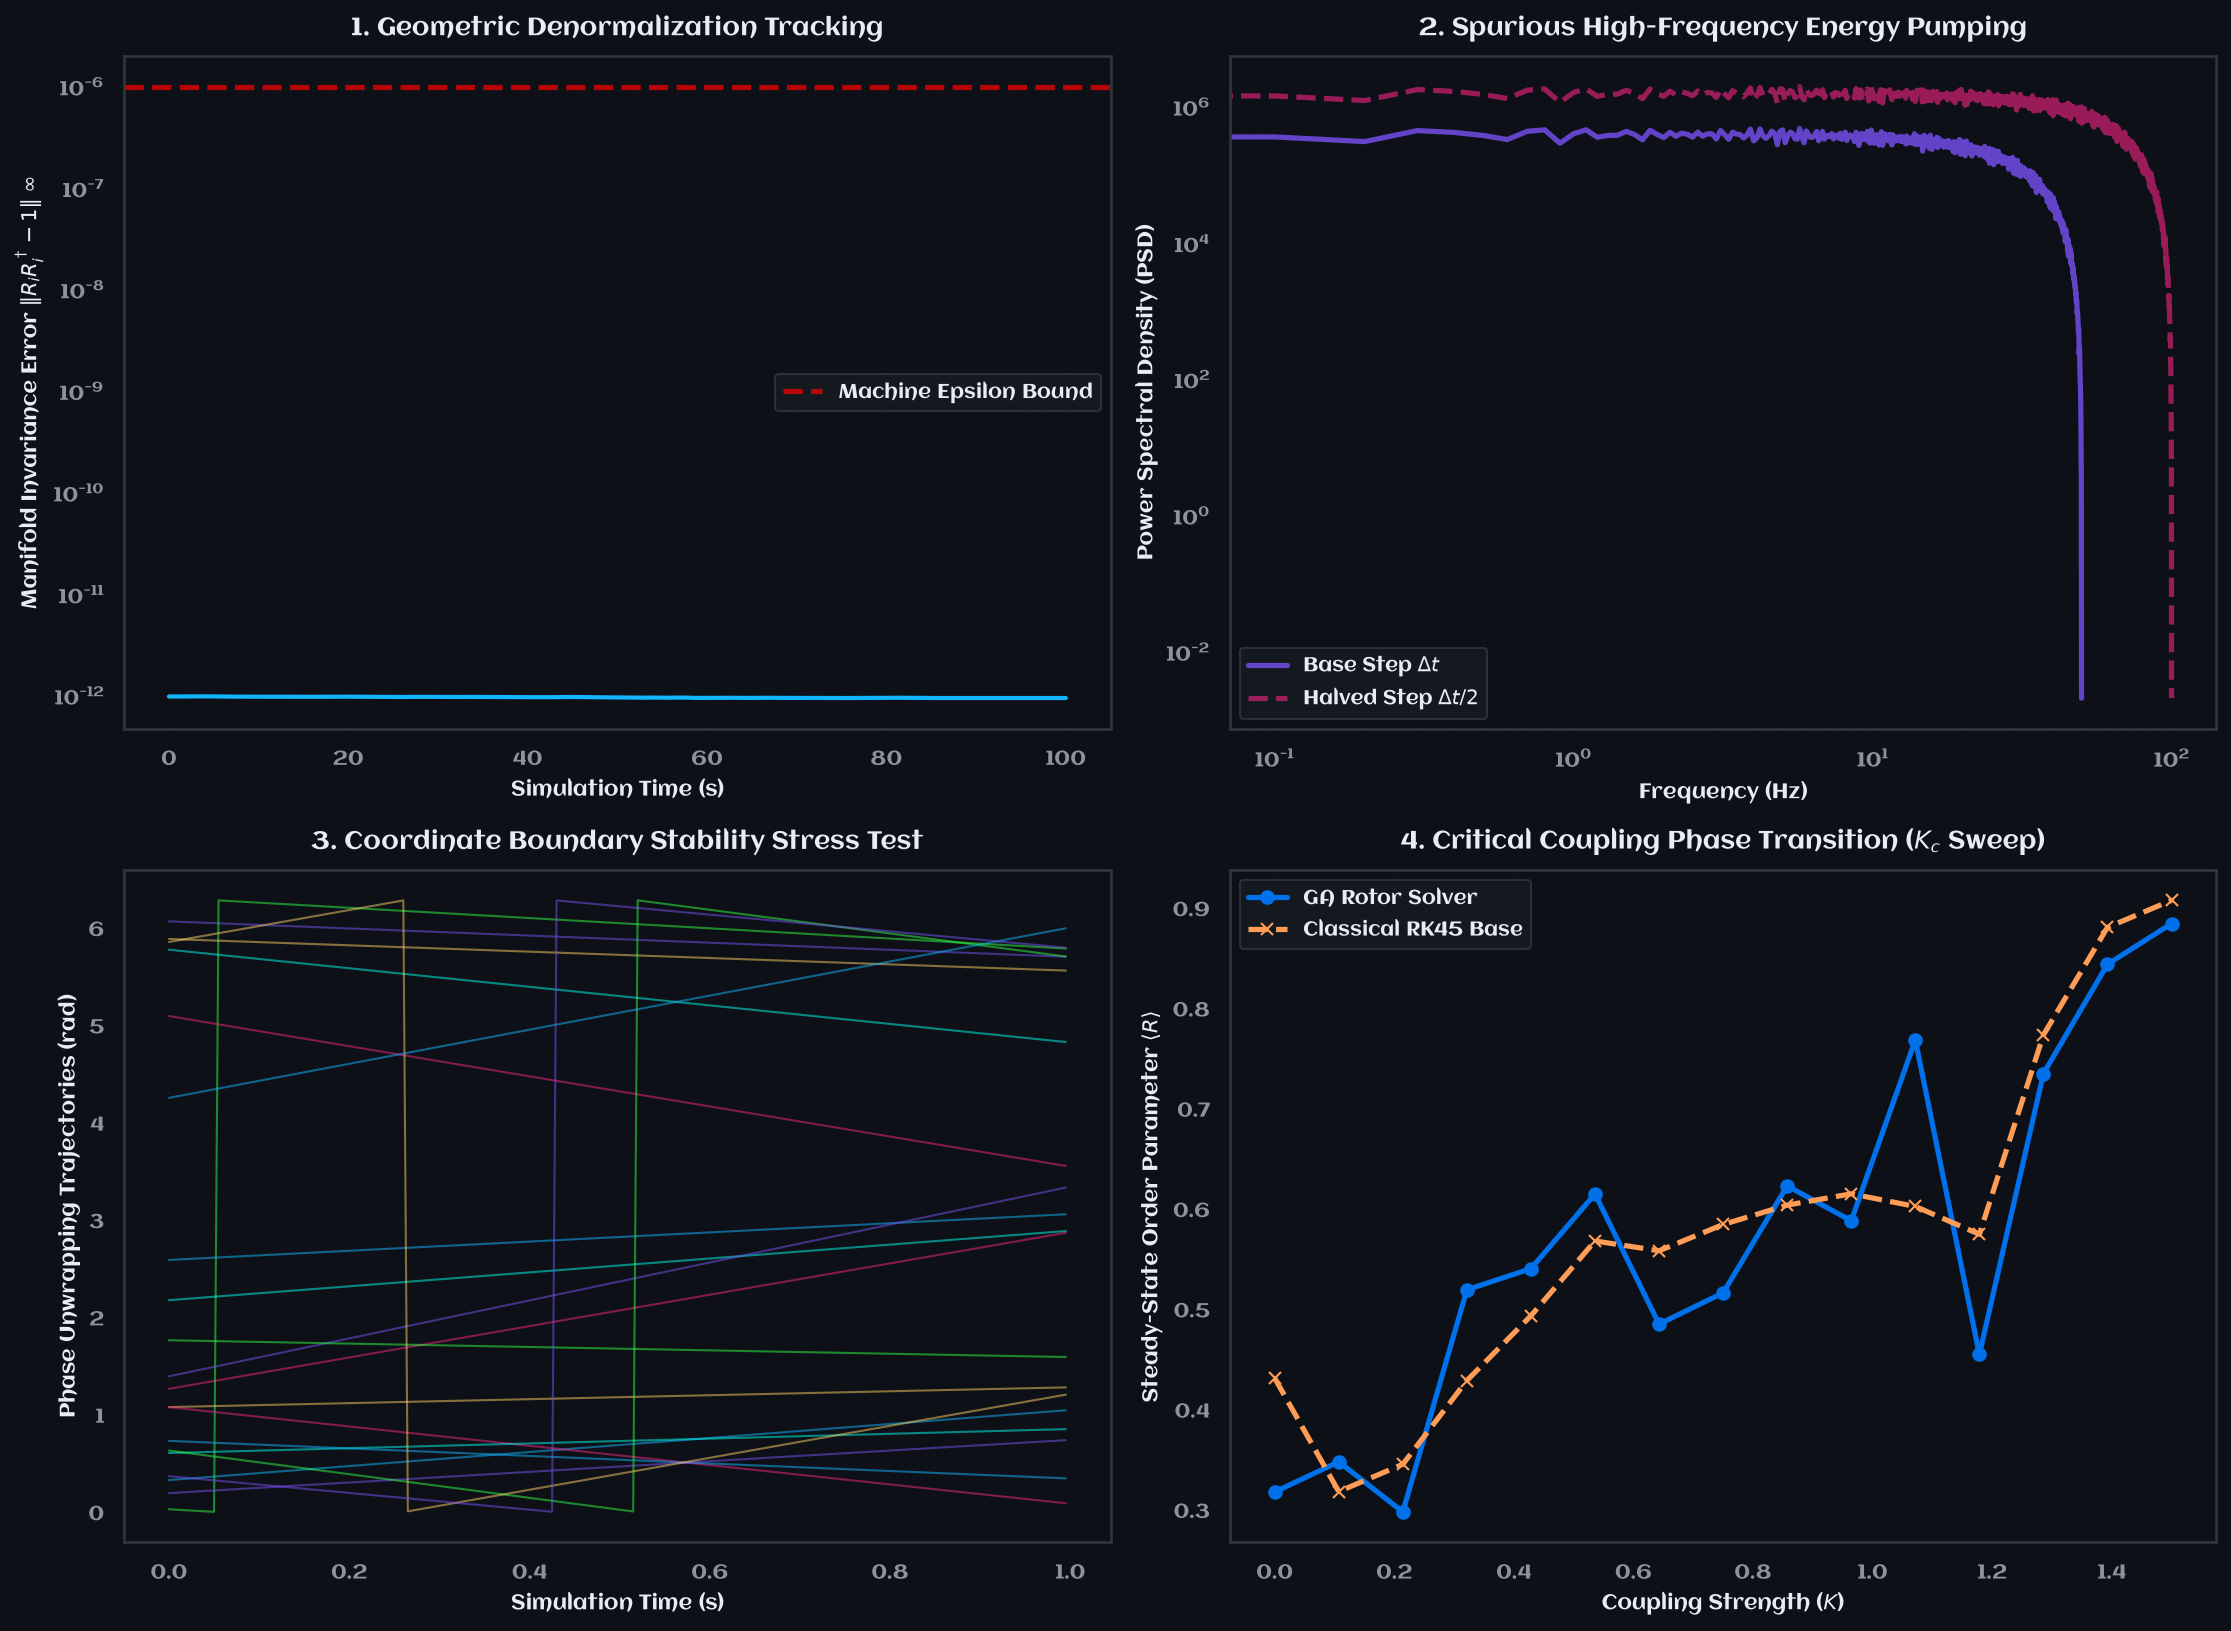

In [13]:
# ==============================================================================
# 📊 VISUAL DIAGNOSTIC MATRIX DISPLAY
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Plot 1: Manifold Drift (Geometric Denormalization)
axes[0, 0].plot(times_long, manifold_drift, color=SCRIBER_PALETTE["accent_cyan"], lw=2.0)
axes[0, 0].axhline(1e-6, color='red', linestyle='--', alpha=0.7, label='Machine Epsilon Bound')
axes[0, 0].set_yscale('log')
axes[0, 0].set_title("1. Geometric Denormalization Tracking", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Simulation Time (s)", fontsize=10)
axes[0, 0].set_ylabel(r"Manifold Invariance Error $\|R_i R_i^\dagger - 1\|_ \infty$", fontsize=10)
axes[0, 0].legend()
axes[0, 0].grid(True, which="both", alpha=0.1)

# Plot 2: Aliasing Sensitivity Check
axes[0, 1].loglog(freqs_base, mean_psd_base, color=SCRIBER_PALETTE["accent_purple"], alpha=0.8, label=r"Base Step $\Delta t$")
axes[0, 1].loglog(freqs_half, mean_psd_half, color=SCRIBER_PALETTE["accent_pink"], alpha=0.6, linestyle="--", label=r"Halved Step $\Delta t / 2$")
axes[0, 1].set_title("2. Spurious High-Frequency Energy Pumping", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Frequency (Hz)", fontsize=10)
axes[0, 1].set_ylabel("Power Spectral Density (PSD)", fontsize=10)
axes[0, 1].legend()
axes[0, 1].grid(True, which="both", alpha=0.1)

# Plot 3: Coordinate Singularity Scatter
axes[1, 0].plot(times_long[:200], simulated_phases_chaos[:200], alpha=0.5, lw=1.0)
axes[1, 0].set_title("3. Coordinate Boundary Stability Stress Test", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Simulation Time (s)", fontsize=10)
axes[1, 0].set_ylabel("Phase Unwrapping Trajectories (rad)", fontsize=10)
axes[1, 0].grid(True, alpha=0.1)

# Plot 4: Symplectic Drift / Phase-Transition Mismatch Mapping
axes[1, 1].plot(coupling_strengths, order_param_rotor, '-o', color=SCRIBER_PALETTE["accent_blue"], label="GA Rotor Solver")
axes[1, 1].plot(coupling_strengths, order_param_rk45, '--x', color=SCRIBER_PALETTE["accent_orange"], label="Classical RK45 Base")
axes[1, 1].set_title(r"4. Critical Coupling Phase Transition ($K_c$ Sweep)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Coupling Strength ($K$)", fontsize=10)
axes[1, 1].set_ylabel("Steady-State Order Parameter $\\langle R \\rangle$", fontsize=10)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.1)

plt.tight_layout()
plt.show()
